# FIN 6465 — Chapter 4 Mini-Project
## Constructing the Balance Sheet in Python

**Financial Modeling with Python — Chapter 4: Constructing the Balance Sheet**

> **Guiding question:** Given the firm's income statement and a disciplined set of working-capital, PP&E, and equity drivers, does your balance sheet close by construction in every period, and is the implied cash position economically plausible?


### Student information

| | |
|---|---|
| **Name** | Sophia Parra |
| **UF email** | *sophiaparra@ufl.edu* |
| **Section** | R222 (4:05 PM) |
| **Team members** | Aman Vyas, Casey Foran, Caleb D'Antonio |
| **Team company (ticker)** | Quanta Services (PWR) |
| **Generative AI tools used** | Claude |


---
## Setup

Run these cells to check your environment and load the FMP helper. The key setup is the same as Week 1; if `FMP_API_KEY` is already set, nothing else is needed.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print(f"Python     {sys.version.split()[0]}")
print(f"NumPy      {np.__version__}")
print(f"pandas     {pd.__version__}")
print(f"Matplotlib {matplotlib.__version__}")

Python     3.12.8
NumPy      1.26.4
pandas     2.2.2
Matplotlib 3.9.2


In [2]:
import os, json
from pathlib import Path
from getpass import getpass
import requests

FMP_BASE = "https://financialmodelingprep.com/stable"
CACHE_DIR = Path("fmp_cache")
CACHE_DIR.mkdir(exist_ok=True)

FMP_API_KEY = os.environ.get("FMP_API_KEY") or getpass("Paste your team's FMP API key (input is hidden): ")


def fmp_get(endpoint, symbol, period="quarter", limit=24, use_cache=True):
    """Fetch one FMP endpoint for a ticker and return a DataFrame (most recent period first).

    Quarterly statements are the course default (at least 20 quarters = 5 years);
    pass period="annual" only for the annual 10-K cross-check.

    endpoint : "income-statement", "balance-sheet-statement", or "cash-flow-statement"
    symbol   : ticker, e.g. "AAPL"
    period   : "quarter" (10-Q, plus the fiscal Q4 from the 10-K; default) or "annual" (10-K)
    limit    : number of periods to return (default 24 quarters)
    """
    symbol = symbol.upper().strip()
    cache_file = CACHE_DIR / f"{symbol}_{endpoint}_{period}_{limit}.json"
    if use_cache and cache_file.exists():
        data = json.loads(cache_file.read_text())
    else:
        params = {"symbol": symbol, "period": period, "limit": limit, "apikey": FMP_API_KEY}
        response = requests.get(f"{FMP_BASE}/{endpoint}", params=params, timeout=30)
        if response.status_code != 200:
            raise RuntimeError(f"FMP returned HTTP {response.status_code}: {response.text[:300]}")
        data = response.json()
        if isinstance(data, dict):   # FMP reports problems as a JSON object
            raise RuntimeError(f"FMP error for {symbol}: {data}")
        if not data:
            raise ValueError(f"No data returned for {symbol} ({endpoint}). Check the ticker.")
        cache_file.write_text(json.dumps(data))
    return pd.DataFrame(data)


def pick(df, field, row=0):
    """Return one value from an FMP statement: `field` in row `row` (0 = most recent period)."""
    if field not in df.columns:
        raise KeyError(f"'{field}' is not a column. Look at df.columns to find the right field name.")
    value = df.iloc[row][field]
    if pd.isna(value):
        raise ValueError(f"'{field}' is empty for row {row}. Check the 10-Q (or the 10-K for a fiscal Q4) and choose another field.")
    return float(value)

print("FMP helper ready. API key loaded:", bool(FMP_API_KEY))

FMP helper ready. API key loaded: True


### Quarterly helpers (provided)


In [3]:
# ---- Quarterly helpers (provided) -------------------------------------------------
# Every mini-project uses at least five years of QUARTERLY data (20 quarters of 10-Q/10-K
# filings). Flows (revenue, net income, CFO, CapEx, ...) are summed across quarters;
# stocks (balance-sheet items) are read at a quarter-end date.
MIN_QUARTERS = 20   # course requirement: at least 5 years x 4 quarters


def quarterly_frame(df, scale=1.0):
    """Return an FMP quarterly statement sorted oldest -> newest, indexed by labels like 'FY2025Q3'.

    Adds three columns: fiscal_year (int), fiscal_q (1-4) and period_end (Timestamp).
    Numeric columns are divided by `scale` (1e6 -> USD millions); ratios such as EPS are not
    special-cased, so divide only the statements you need in dollars.
    """
    out = df.copy()
    if "fiscalYear" in out.columns:
        fy = out["fiscalYear"].astype(int)
    else:
        fy = pd.to_datetime(out["date"]).dt.year
    q = out["period"].astype(str).str.upper().str.replace("Q", "", regex=False)
    if not q.isin(["1", "2", "3", "4"]).all():
        raise ValueError("Expected period values Q1-Q4. Did you call fmp_get(..., period='quarter')?")
    out["fiscal_year"] = fy.values
    out["fiscal_q"] = q.astype(int).values
    out["period_end"] = pd.to_datetime(out["date"]).values
    out = out.sort_values(["fiscal_year", "fiscal_q"])
    out.index = [f"FY{y}Q{qq}" for y, qq in zip(out["fiscal_year"], out["fiscal_q"])]
    keep = {"fiscal_year", "fiscal_q", "period_end"}
    num = [c for c in out.columns if c not in keep and pd.api.types.is_numeric_dtype(out[c])]
    out[num] = out[num] / scale
    return out


def check_quarters(q, min_quarters=MIN_QUARTERS):
    """PASS/FAIL detail for the quarterly coverage rule: enough quarters, unique, no gaps."""
    n = len(q)
    unique = q.index.is_unique
    seq = q["fiscal_year"] * 4 + q["fiscal_q"]
    no_gaps = bool((seq.diff().dropna() == 1).all())
    passed = (n >= min_quarters) and unique and no_gaps
    detail = f"{n} quarters ({q.index[0]} to {q.index[-1]}); unique={unique}; consecutive={no_gaps}"
    return passed, detail


def ttm(series):
    """Trailing-twelve-month sum of a quarterly FLOW series (NaN until four quarters exist)."""
    return series.rolling(4).sum()


def to_fiscal_years(q, flow_cols=(), stock_cols=()):
    """Aggregate quarters to complete fiscal years: flows are summed, stocks use the Q4 value.

    Only fiscal years with all four quarters are returned, so a partial current year is dropped.
    """
    complete = q.groupby("fiscal_year")["fiscal_q"].nunique()
    years = complete[complete == 4].index
    qq = q[q["fiscal_year"].isin(years)]
    parts = []
    if flow_cols:
        parts.append(qq.groupby("fiscal_year")[list(flow_cols)].sum())
    if stock_cols:
        parts.append(qq[qq["fiscal_q"] == 4].set_index("fiscal_year")[list(stock_cols)])
    out = pd.concat(parts, axis=1)
    out.index.name = "fiscal_year"
    return out

### Settings

In [4]:
# ===================== SETTINGS =====================
SYMBOL = "PWR"                
FILE_STEM = "FIN6465_MP4_Parra_Sophia"   
MP3_FORECAST_CSV = "FIN6465_MP3_Parra_Sophia_forecast.csv"   # your Week 3 export, copied into this folder
N_QUARTERS = 24              # >= 20 required (5 years); 24 guarantees 5 complete fiscal years
SCALE = 1e6
UNITS = "USD millions"
DAYS = 365

# Field map: model name -> (statement, FMP field). Confirm with the column lists in Section 2.1.
# Income and cash flow fields are flows (summed over quarters); balance sheet fields are stocks (quarter-end).
FIELD_MAP = {
    # income statement (history)
    "revenue":          ("income", "revenue"),
    "cogs":             ("income", "costOfRevenue"),
    "da":               ("income", "depreciationAndAmortization"),
    "net_income":       ("income", "netIncome"),
    "interest_expense": ("income", "interestExpense"),
    # balance sheet: current assets
    "cash":             ("balance", "cashAndShortTermInvestments"),
    "ar":               ("balance", "netReceivables"),          # may include contract assets
    "inventory":        ("balance", "inventory"),
    "other_current_assets": ("balance", "otherCurrentAssets"),  # added: prepaids (and possibly contract assets)
    "current_assets":   ("balance", "totalCurrentAssets"),
    # balance sheet: non-current assets
    "ppe_net":          ("balance", "propertyPlantEquipmentNet"),
    "goodwill":         ("balance", "goodwill"),                # added
    "intangibles":      ("balance", "intangibleAssets"),        # added
    "other_noncurrent_assets": ("balance", "otherNonCurrentAssets"),  # added
    "total_assets":     ("balance", "totalAssets"),
    # balance sheet: current liabilities
    "ap":               ("balance", "accountPayables"),         # PWR reports AP + accrued expenses together
    "deferred_revenue": ("balance", "deferredRevenue"),         # PWR calls this "contract liabilities"
    "short_term_debt":  ("balance", "shortTermDebt"),
    "other_current_liabilities": ("balance", "otherCurrentLiabilities"),  # added
    "current_liabilities": ("balance", "totalCurrentLiabilities"),
    # balance sheet: non-current liabilities
    "long_term_debt":   ("balance", "longTermDebt"),            # added
    "deferred_taxes":   ("balance", "deferredTaxLiabilitiesNonCurrent"),  # added
    "other_noncurrent_liabilities": ("balance", "otherNonCurrentLiabilities"),  # added
    "debt":             ("balance", "totalDebt"),               # check: may include lease liabilities
    "total_liabilities": ("balance", "totalLiabilities"),
    # balance sheet: equity
    "retained_earnings": ("balance", "retainedEarnings"),
    "stockholders_equity": ("balance", "totalStockholdersEquity"),  # added: excludes NCI
    "minority_interest": ("balance", "minorityInterest"),       # added
    "total_equity":     ("balance", "totalEquity"),
    # cash flow statement (stored as positive magnitudes in Section 2.1)
    "capex":            ("cashflow", "capitalExpenditure"),
    "dividends":        ("cashflow", "commonDividendsPaid"),    # some companies: "netDividendsPaid"
}

In [5]:
import os; os.path.exists(MP3_FORECAST_CSV)

True

---
## 2.1 Data Ingestion and Opening Balances


In [6]:
def build_quarterly_pack(statements, field_map, scale):
    """Combine FMP quarterly statements into one table indexed by quarter label (oldest first)."""
    frames = {stmt: quarterly_frame(df) for stmt, df in statements.items()}
    q = frames["balance"][["fiscal_year", "fiscal_q", "period_end"]].copy()
    for name, (stmt, field) in field_map.items():
        df = frames[stmt]
        if field not in df.columns:
            raise KeyError(f"'{field}' is not in the {stmt} statement. Check FIELD_MAP against the column lists.")
        q[name] = df[field].astype(float).reindex(q.index) / scale
    return q

statements = {
    "income":   fmp_get("income-statement", SYMBOL, period="quarter", limit=N_QUARTERS),
    "balance":  fmp_get("balance-sheet-statement", SYMBOL, period="quarter", limit=N_QUARTERS),
    "cashflow": fmp_get("cash-flow-statement", SYMBOL, period="quarter", limit=N_QUARTERS),
}
for name in ["balance", "cashflow"]:
    print(f"{name} fields:\n{list(statements[name].columns)}\n")

hist_q = build_quarterly_pack(statements, FIELD_MAP, SCALE)
hist_q[["capex", "dividends"]] = hist_q[["capex", "dividends"]].abs()     # positive magnitudes

FLOWS = [n for n, (stmt, _) in FIELD_MAP.items() if stmt in ("income", "cashflow")]   # summed over quarters
STOCKS = [n for n, (stmt, _) in FIELD_MAP.items() if stmt == "balance"]               # fiscal Q4 balance
hist = to_fiscal_years(hist_q, flow_cols=FLOWS, stock_cols=STOCKS)[list(FIELD_MAP)]
partial = hist_q[hist_q["fiscal_year"] > hist.index[-1]]

# Week 3 forecast: keep forecast rows ("E"), index by integer fiscal year
mp3 = pd.read_csv(MP3_FORECAST_CSV, index_col=0)
mp3 = mp3[mp3.index.str.endswith("E")]
mp3.index = mp3.index.str[2:6].astype(int)
is_forecast = mp3[["revenue", "cogs", "da", "net_income", "net_interest"]]

print(f"Quarters: {hist_q.index[0]}-{hist_q.index[-1]} ({len(hist_q)})  |  Complete fiscal years: FY{hist.index[0]}-FY{hist.index[-1]}")
print(f"Opening balance sheet: FY{hist.index[-1]}Q4 (period end {hist_q.loc[f'FY{hist.index[-1]}Q4', 'period_end'].date()})")
if len(partial):
    print(f"Partial FY{partial['fiscal_year'].iloc[0]} ({', '.join(partial.index)}): year-to-date cross-check only, not in the annual model")
print(f"Week 3 forecast starts the year after the last complete fiscal year: {is_forecast.index[0] == hist.index[-1] + 1}")
print(f"History: FY{hist.index[0]}-FY{hist.index[-1]}  |  Forecast: FY{is_forecast.index[0]}-FY{is_forecast.index[-1]}  ({UNITS})")
display(hist.T.round(1))
display(is_forecast.T.round(1))

balance fields:
['date', 'symbol', 'reportedCurrency', 'cik', 'filingDate', 'acceptedDate', 'fiscalYear', 'period', 'cashAndCashEquivalents', 'shortTermInvestments', 'cashAndShortTermInvestments', 'netReceivables', 'accountsReceivables', 'otherReceivables', 'inventory', 'prepaids', 'otherCurrentAssets', 'totalCurrentAssets', 'propertyPlantEquipmentNet', 'goodwill', 'intangibleAssets', 'goodwillAndIntangibleAssets', 'longTermInvestments', 'taxAssets', 'otherNonCurrentAssets', 'totalNonCurrentAssets', 'otherAssets', 'totalAssets', 'totalPayables', 'accountPayables', 'otherPayables', 'accruedExpenses', 'shortTermDebt', 'capitalLeaseObligationsCurrent', 'taxPayables', 'deferredRevenue', 'otherCurrentLiabilities', 'totalCurrentLiabilities', 'longTermDebt', 'capitalLeaseObligationsNonCurrent', 'deferredRevenueNonCurrent', 'deferredTaxLiabilitiesNonCurrent', 'otherNonCurrentLiabilities', 'totalNonCurrentLiabilities', 'otherLiabilities', 'capitalLeaseObligations', 'totalLiabilities', 'treasury

fiscal_year,2021,2022,2023,2024,2025
revenue,12980.2,17073.9,20882.2,23672.8,28351.5
cogs,11192.3,14898.7,18234.1,20545.0,24657.4
da,420.9,644.6,613.8,742.3,910.3
net_income,486.0,491.2,744.7,904.8,1028.4
interest_expense,68.9,124.4,186.9,202.7,261.4
cash,229.1,428.5,1290.2,742.0,439.5
ar,4203.8,4754.7,5823.9,6379.6,8369.3
inventory,84.7,103.3,175.7,260.2,370.4
other_current_assets,0.0,249.6,387.1,469.3,724.3
current_assets,4732.6,5536.1,7676.9,7851.0,9903.4


fiscal_year,2026,2027,2028,2029,2030
revenue,41393.2,53811.1,64573.3,74259.3,81685.3
cogs,36094.8,46923.3,56308.0,64754.1,71229.6
da,1366.0,1775.8,2130.9,2450.6,2695.6
net_income,1526.4,2034.8,2472.3,2864.6,3161.8
net_interest,281.5,300.0,320.0,340.0,360.0



| Assets | Liabilities | Equity |
|---|---|---|
| cash (plug in the forecast) | ap | retained_earnings |
| ar | deferred_revenue | other_equity (contributed capital, AOCI, treasury stock, noncontrolling interest) |
| inventory | other_current_liabilities | |
| other_current_assets | debt | |
| ppe_net | other_noncurrent_liabilities | |
| other_noncurrent_assets | | |

- other_current_assets = current_assets − cash − ar − inventory
- other_noncurrent_assets = total_assets − current_assets − ppe_net
- other_current_liabilities = current_liabilities − ap − deferred_revenue − short_term_debt
- other_noncurrent_liabilities = total_liabilities − current_liabilities − (debt − short_term_debt)
- other_equity = total_equity − retained_earnings

In [7]:
BS_ASSETS = ["cash", "ar", "inventory", "other_current_assets", "ppe_net", "other_noncurrent_assets"]
BS_LIABILITIES = ["ap", "deferred_revenue", "other_current_liabilities", "debt", "other_noncurrent_liabilities"]
BS_EQUITY = ["retained_earnings", "other_equity"]

# Build `opening` (historical balance sheet in the model's structure)
q4 = hist.copy()

opening = pd.DataFrame(index=q4.index)
opening["cash"] = q4["cash"]
opening["ar"] = q4["ar"]
opening["inventory"] = q4["inventory"]
opening["other_current_assets"] = q4["current_assets"] - q4["cash"] - q4["ar"] - q4["inventory"]
opening["ppe_net"] = q4["ppe_net"]
opening["other_noncurrent_assets"] = q4["total_assets"] - q4["current_assets"] - q4["ppe_net"]

opening["ap"] = q4["ap"]
opening["deferred_revenue"] = q4["deferred_revenue"]
opening["other_current_liabilities"] = q4["current_liabilities"] - q4["ap"] - q4["deferred_revenue"] - q4["short_term_debt"]
opening["debt"] = q4["debt"]
opening["other_noncurrent_liabilities"] = q4["total_liabilities"] - q4["current_liabilities"] - (q4["debt"] - q4["short_term_debt"])

opening["retained_earnings"] = q4["retained_earnings"]
opening["other_equity"] = q4["total_equity"] - q4["retained_earnings"]

opening = opening[BS_ASSETS + BS_LIABILITIES + BS_EQUITY]

# check: assets = liabilities + equity in every year
gap = opening[BS_ASSETS].sum(axis=1) - opening[BS_LIABILITIES + BS_EQUITY].sum(axis=1)
assert (gap.abs() < 1e-6).all(), gap
total_assets = opening[BS_ASSETS].sum(axis=1)
pct = opening.div(total_assets, axis=0) * 100
display(pct.T.round(1))
display(opening.T.round(1))

fiscal_year,2021,2022,2023,2024,2025
cash,1.8,3.2,7.9,4.0,1.8
ar,32.7,35.3,35.9,34.1,33.6
inventory,0.7,0.8,1.1,1.4,1.5
other_current_assets,1.7,1.9,2.4,2.5,2.9
ppe_net,16.8,16.8,15.9,16.1,15.5
other_noncurrent_assets,46.4,42.1,36.8,41.9,44.8
ap,9.7,9.7,12.5,11.2,11.4
deferred_revenue,6.2,8.5,9.5,11.5,13.1
other_current_liabilities,8.4,6.9,6.8,9.2,7.5
debt,31.1,29.5,27.5,24.0,25.8


fiscal_year,2021,2022,2023,2024,2025
cash,229.1,428.5,1290.2,742.0,439.5
ar,4203.8,4754.7,5823.9,6379.6,8369.3
inventory,84.7,103.3,175.7,260.2,370.4
other_current_assets,215.1,249.6,387.1,469.3,724.3
ppe_net,2160.3,2260.2,2586.4,3000.2,3856.0
other_noncurrent_assets,5962.3,5668.1,5973.9,7832.7,11167.5
ap,1251.1,1302.1,2027.6,2096.1,2832.6
deferred_revenue,802.9,1141.5,1538.7,2149.3,3258.5
other_current_liabilities,1081.8,925.1,1111.6,1720.4,1861.2
debt,4002.3,3975.5,4463.7,4479.0,6419.0


✍️ **Data notes:** Units, currency, and fiscal year-end (do Weeks 3 and 4 align?). Which quarters did you load, which fiscal year is the last complete one, and what is the date of your opening (Q4) balance sheet? How large are the "other" lines relative to total assets, and what do they mainly contain (check the 10-K for the fiscal Q4 balance sheet, or the 10-Q for an interim quarter; name the filing, the statement, and the line item)? Note any negative "other" balances, `FIELD_MAP` edits, or reclassifications.

Weeks 3 and 4 are both in USD millions and both use Quanta's December 31 fiscal year-end, and the Week 3 forecast (FY2026E–FY2030E) starts the year after the last complete fiscal year. I loaded 24 quarters, FY2020Q4–FY2026Q3. FY2025 is the last complete fiscal year, so the opening balance sheet is FY2025Q4, dated December 31, 2025. FY2026Q1–Q3 are a year-to-date cross-check only.

Other non current assets is by far the largest other line at about 45% of total assets (11,167.5M in FY2025), and most of that is goodwill (7,317.2M) and intangible assets (2,906.2M) from Quanta’s acquisitions, which are shown on the consolidated balance sheet in the 2025 10-K. The remaining 944M is other assets, which include retainage balances with expected settlement dates beyond one year and corporate owned life insurance policies covering participants in the deferred compensation plans, which I found on pages 80 and 105 of the 2025 10-K. Other current liabilities are about 7.5% of assets and are mostly accrued compensation (781.6M) and other accrued expenses (965.2M) like insurance reserves and taxes payable. Other non current liabilities are about 6.1% and are mostly insurance and other non current liabilities plus deferred income taxes. Other equity is about 9.4% and includes paid in capital, treasury stock, AOCI, and non controlling interests, and other current assets are only about 2.9% and are mostly prepaid expenses. None of the other lines are negative in any year. I added fields to the FIELD_MAP for goodwill, intangibles, deferred taxes, and the other current and non current lines so I could see what the other lines contained. The main thing I noted is that FMP includes contract assets in AR, calls contract liabilities deferred revenue, and includes lease liabilities in total debt. Also, for FY2026Q3 only, FMP used the combined accounts payable and accrued expenses line, so I replaced it with trade AP of 4,259.4M from the Q3 10-Q footnote.

---
## Historical Drivers and Assumptions

In [8]:

h = hist.sort_index()

hist_drivers = pd.DataFrame({
    "dso":                 h["ar"] / h["revenue"] * DAYS,
    "dio":                 h["inventory"] / h["cogs"] * DAYS,
    "dpo":                 h["ap"] / h["cogs"] * DAYS,
    "capex_pct_revenue":   h["capex"] / h["revenue"],
    "dep_rate":            h["da"] / h["ppe_net"].shift(1),              # D&A / prior-year net PP&E
    "payout_ratio":        h["dividends"] / h["net_income"],
    "interest_rate":       h["interest_expense"] / ((h["debt"] + h["debt"].shift(1)) / 2),  # / average debt
    "deferred_pct_revenue": h["deferred_revenue"] / h["revenue"],
}, index=h.index).replace([np.inf, -np.inf], np.nan)

hist_drivers.insert(3, "ccc", hist_drivers["dso"] + hist_drivers["dio"] - hist_drivers["dpo"])

display(hist_drivers.T.round(3))

fiscal_year,2021,2022,2023,2024,2025
dso,118.209,101.645,101.796,98.363,107.747
dio,2.761,2.530,3.516,4.622,5.483
dpo,40.801,31.899,40.587,37.240,41.931
ccc,80.169,72.275,64.725,65.746,71.299
capex_pct_revenue,0.030,0.025,0.021,0.026,0.021
dep_rate,NaN,0.298,0.272,0.287,0.303
payout_ratio,0.070,0.084,0.064,0.060,0.059
interest_rate,NaN,0.031,0.044,0.045,0.048
deferred_pct_revenue,0.062,0.067,0.074,0.091,0.115


AP fix applied to FY2026Q3: combined AP+accrued -> trade AP
Quarterly calibration: FY2021Q3-FY2026Q3 (21 quarter-ends with a TTM flow)


,mean,min,max,q4_mean,n_quarters
dso,105.337,91.221,118.209,105.552,21
dio,4.093,2.210,6.294,3.782,21
dpo,39.115,31.899,49.135,38.492,21
ccc,70.315,59.674,82.823,70.843,21
capex_pct_revenue,0.025,0.021,0.030,0.025,21
dep_rate,0.291,0.232,0.370,0.278,20
payout_ratio,0.066,0.039,0.091,0.067,21
interest_rate,0.041,0.028,0.050,0.040,20
deferred_pct_revenue,0.079,0.042,0.148,0.082,21


,dso,dio,dpo,ccc
fiscal quarter (seasonality check: average days),,,,
1,102.6,4.3,37.2,69.7
2,103.0,4.3,39.3,68.0
3,109.4,4.0,41.1,72.3
4,105.6,3.8,38.5,70.8


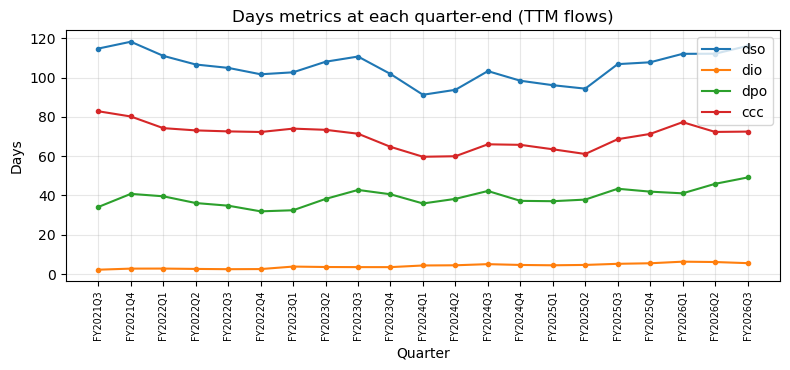

In [9]:
# Quarterly driver calibration (provided): TTM flows against quarter-end balances

# --- Data fix: FY2026Q3 AP --------------------------------------------------
# For FY2026Q3, FMP reported the combined "accounts payable and accrued expenses"
# line ($7,189.7M) instead of trade AP, which every prior quarter uses.
# Q3 10-Q footnote: 7,189,693 - 1,361,148 (accrued comp) - 1,569,140 (other accrued)
#                   = 4,259,405 trade AP ($000s). Scaling the existing value by the
# trade/combined ratio keeps the fix correct whatever units hist_q uses.
AP_FIX_Q = "FY2026Q3"
if AP_FIX_Q in hist_q.index:
    q_prev = hist_q.index[hist_q.index.get_loc(AP_FIX_Q) - 1]
    if hist_q.loc[AP_FIX_Q, "ap"] / hist_q.loc[q_prev, "ap"] > 1.6:   # still the combined line
        hist_q.loc[AP_FIX_Q, "ap"] *= 4_259_405 / 7_189_693
        print(f"AP fix applied to {AP_FIX_Q}: combined AP+accrued -> trade AP")

# Guard: flag any other quarter where AP jumps enough to suggest a definition change
ap_qoq = hist_q["ap"].pct_change()
if ap_qoq.abs().max() > 0.4:
    print(f"WARNING: AP moved {ap_qoq.abs().max():.0%} at {ap_qoq.abs().idxmax()}; check the definition")
# -----------------------------------------------------------------------------

ttm_rev, ttm_cogs = ttm(hist_q["revenue"]), ttm(hist_q["cogs"])
q_drivers = pd.DataFrame({
    "fiscal_q":             hist_q["fiscal_q"],
    "dso":                  hist_q["ar"] / ttm_rev * DAYS,
    "dio":                  hist_q["inventory"] / ttm_cogs * DAYS,
    "dpo":                  hist_q["ap"] / ttm_cogs * DAYS,
    "capex_pct_revenue":    ttm(hist_q["capex"]) / ttm_rev,
    "dep_rate":             ttm(hist_q["da"]) / hist_q["ppe_net"].shift(4),              # TTM D&A / net PP&E 4 quarters earlier
    "payout_ratio":         ttm(hist_q["dividends"]) / ttm(hist_q["net_income"]),
    "interest_rate":        ttm(hist_q["interest_expense"]) / hist_q["debt"].rolling(5).mean(),  # TTM interest / average debt
    "deferred_pct_revenue": hist_q["deferred_revenue"] / ttm_rev,
}).replace([np.inf, -np.inf], np.nan)
q_drivers.insert(4, "ccc", q_drivers["dso"] + q_drivers["dio"] - q_drivers["dpo"])
q_drivers = q_drivers.dropna(subset=["dso"])      # the first three quarters have no TTM flow

metrics = q_drivers.drop(columns="fiscal_q")
anchor = pd.DataFrame({"mean": metrics.mean(), "min": metrics.min(), "max": metrics.max(),
                       "q4_mean": metrics[q_drivers["fiscal_q"] == 4].mean(), "n_quarters": metrics.count()})
print(f"Quarterly calibration: {q_drivers.index[0]}-{q_drivers.index[-1]} ({len(q_drivers)} quarter-ends with a TTM flow)")
display(anchor.round(3))
display(q_drivers.groupby("fiscal_q")[["dso", "dio", "dpo", "ccc"]].mean().round(1)
        .rename_axis("fiscal quarter (seasonality check: average days)"))

fig, ax = plt.subplots(figsize=(8, 3.8))
q_drivers[["dso", "dio", "dpo", "ccc"]].plot(ax=ax, marker=".")
ax.set_xticks(range(len(q_drivers))); ax.set_xticklabels(q_drivers.index, rotation=90, fontsize=7)
ax.set(title="Days metrics at each quarter-end (TTM flows)", xlabel="Quarter", ylabel="Days")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Driver assumptions (all forecast inputs live here)



In [10]:
# ============== DRIVER ASSUMPTIONS ==============
SCENARIO = "base"
MODEL_VERSION = "1.0"

DSO = 105.0                  # days of revenue in receivables      | why: Q4 mean 105.6, 21-qtr mean 105.3 (range 91-118); includes contract assets, kept near the anchor
DIO = 4.0                    # days of COGS in inventory           | why: Q4 mean 3.8, mean 4.1 (range 2.2-6.3); service contractor, inventory is minor materials
DPO = 39.0                   # days of COGS in payables            | why: Q4 mean 38.5, mean 39.1 (range 31.9-49.1) after replacing FY2026Q3 combined AP+accrued ($7.19B) with trade AP ($4.26B)
DEFERRED_PCT_REVENUE = 0.08  # deferred revenue as % of revenue    | why: contract liabilities (billings in excess); Q4 mean 8.2%, mean 7.9% (range 4.2-14.8%); FY2026Q3 high assumed to unwind. Project-based, not subscription, so % of revenue is fine
CAPEX_PCT_REVENUE = 0.025    # growth-level CapEx                  | why: mean and Q4 mean both 2.5% (range 2.1-3.0%); ~2x depreciation, i.e. fleet/equipment growth
PAYOUT_RATIO = 0.065         # dividends / net income              | why: mean 6.6%, Q4 mean 6.7% (range 3.9-9.1%); small, steady dividend that grows slower than earnings
DEBT_PATH = "flat"           # exogenous path, "flat" = last actual debt | why: no announced paydown/issuance assumed; acquisitions are funded case by case
INTEREST_RATE = 0.040        # calibrated from history             | why: Q4 mean 4.0%, mean 4.1% (range 2.8-5.0%); rates near current levels
CASH_PLUG_FLAG = 500         # flag forecast years where |cash plug| exceeds this many UNITS (USD millions)



✍️ **Driver logic:** Justify each driver with the history above (cite the years or quarters and values you anchored to, including the quarterly average and range). Is working capital seasonal (compare the Q4 days with the other quarters), and which quarter-end did you anchor to? Is your CapEx a maintenance or a growth level, given the depreciation rate?

 Working capital at Quanta is only mildly seasonal. DSO is lowest in Q1 (102.6 days) and peaks in Q3 (109.4) during the summer construction season. DPO moves in the same direction (37.2 in Q1 to 41.1 in Q3), so the cash conversion cycle stays in a narrow band of 68.0–72.3 days across quarters. Q4 values sit close to the all-quarter averages (DSO 105.6 vs. 105.3, DIO 3.8 vs. 4.1, DPO 38.5 vs. 39.1, CCC 70.8 vs. 70.3). Because the model forecasts fiscal year-end balances, I anchor to the Q4 averages, cross-checked against the 21-quarter mean (FY2021Q3–FY2026Q3). 

DSO = 105 days: The 21-quarter mean is 105.3 (range 91.2–118.2) and the Q4 mean is 105.6; FY2025 year-end was 107.7. DSO has drifted up to roughly 107–116 over the last five quarters as large projects ramped, but it has stayed within the historical range, so I assume it reverts toward the long-run mean. My measure includes contract assets, so it runs higher than Quanta's reported receivables-only figure.

DIO = 4 days: The mean is 4.1 (range 2.2–6.3) and the Q4 mean is 3.8. As a services contractor, Quanta holds inventory mainly as materials for projects, so DIO is immaterial to cash flow. Backlog and RPO are better indicators of demand.

DPO = 39 days: The Q4 mean is 38.5 and the 21-quarter mean is 39.1 (range 31.9–49.1). The raw FMP data showed 82.9 days in FY2026Q3 because it used the combined accounts payable and accrued expenses line (7.19B) instead of trade payables. I replaced it with trade AP of 4.26B from the Q3 2026 10-Q footnote, which gives 49.1 days. That is the high end of the range, but consistent with payables growing alongside a sharp ramp in project costs.

Deferred revenue = 8% of revenue: The mean is 7.9% and the Q4 mean is 8.2%, but the range is wide (4.2%–14.8%). FY2026Q3 is the historical high at 14.8%, as advance billings on large projects grew (contract liabilities rose from 3.26B to 5.54B during 2026). I assume the ratio moves back toward the historical average as those projects are completed. This is a key risk to the cash forecast: a slower unwind would mean more cash.

CapEx = 2.5% of revenue: Both the mean and the Q4 mean are 2.5% (range 2.1–3.0%; annual FY2021–FY2025 2.1–3.0%). This is a growth level, not maintenance. In the first nine months of 2026, CapEx of 719M was about 2.0x depreciation of 351M, reflecting fleet and equipment expansion to support backlog growth. My dep_rate driver (mean 29.1% of prior-year net PP&E) uses total D&A, which includes amortization of acquired intangibles, so it overstates depreciation of physical equipment and shouldn't be compared directly with CapEx.

Payout ratio = 6.5%: The quarterly mean is 6.6% (range 3.9%–9.1%) and the Q4 mean is 6.7%; the annual ratio fell from 8.4% (FY2022) to 5.9% (FY2025). Quanta pays a small, steady dividend that has grown more slowly than earnings, so I set the ratio slightly below the mean.

Debt = flat; interest rate = 4.0%: I hold debt at the last actual balance (6,419.0M) because the brief's default is a flat path, and future acquisitions and financings can't be reliably estimated. The interest rate matches the Q4 mean of 4.0% (overall mean 4.1%, range 2.8%–5.0%; annual 3.1%–4.8%), consistent with current rate levels.

---
## 2.2 Working Capital Schedules

NWC = ar + inventory + other_current_assets − ap − deferred_revenue − other_current_liabilities (operating items only: no cash, no debt).

In [11]:
# ============== 2.2 WORKING CAPITAL SCHEDULES ==============
# History: balances from `opening` (2.1), where other_current_assets / other_current_liabilities are
# residuals against reported totals (so accrued expenses and current lease liabilities are included).
# Forecast: driver-based AR / inventory / AP / deferred revenue; other current items held at last actual.
hist_bs = opening.copy()
hist_is = hist.copy()
fc_is   = is_forecast.copy()
for df in (hist_bs, hist_is, fc_is):
    df.index = df.index.astype(int)

is_all = pd.concat([hist_is[["revenue", "cogs"]], fc_is[["revenue", "cogs"]]]).sort_index()
is_all = is_all[~is_all.index.duplicated(keep="first")]      # history wins if a year appears twice

bal_cols = ["ar", "inventory", "ap", "deferred_revenue",
            "other_current_assets", "other_current_liabilities"]

years    = is_all.index
hist_yrs = years[years.isin(hist_bs.index)]
fc_yrs   = years[~years.isin(hist_bs.index)]
assert len(hist_yrs) and len(fc_yrs), "history or forecast years missing; check opening / is_forecast"
last     = hist_yrs[-1]                                      # last actual year
print(f"History: FY{hist_yrs[0]}-FY{last}  |  Forecast: FY{fc_yrs[0]}-FY{fc_yrs[-1]}")

rev, cogs = is_all["revenue"], is_all["cogs"]

# --- balances ---
wc = pd.DataFrame(index=years, columns=bal_cols, dtype=float)
wc.index.name = "fiscal_year"

# History: actual balances (model structure)
wc.loc[hist_yrs, bal_cols] = hist_bs.loc[hist_yrs, bal_cols].values

# Forecast: driver-based balances
wc.loc[fc_yrs, "ar"]               = rev[fc_yrs]  * DSO / DAYS
wc.loc[fc_yrs, "inventory"]        = cogs[fc_yrs] * DIO / DAYS
wc.loc[fc_yrs, "ap"]               = cogs[fc_yrs] * DPO / DAYS
wc.loc[fc_yrs, "deferred_revenue"] = rev[fc_yrs]  * DEFERRED_PCT_REVENUE

# Other current items held flat at the last actual
wc.loc[fc_yrs, "other_current_assets"]      = hist_bs.loc[last, "other_current_assets"]
wc.loc[fc_yrs, "other_current_liabilities"] = hist_bs.loc[last, "other_current_liabilities"]

# --- NWC (operating items only: no cash, no debt) ---
wc["nwc"] = (wc["ar"] + wc["inventory"] + wc["other_current_assets"]
             - wc["ap"] - wc["deferred_revenue"] - wc["other_current_liabilities"])
wc["delta_nwc"]      = wc["nwc"].diff()                      # first history year has no prior -> NaN
wc["wc_cash_impact"] = -wc["delta_nwc"]                      # NWC build = cash outflow

# --- days metrics (history = implied from actuals; forecast = drivers) ---
wc["dso"] = wc["ar"] / rev * DAYS
wc["dio"] = wc["inventory"] / cogs * DAYS
wc["dpo"] = wc["ap"] / cogs * DAYS
wc["ccc"] = wc["dso"] + wc["dio"] - wc["dpo"]

# --- sanity checks ---
assert np.allclose(wc.loc[fc_yrs, ["dso", "dio", "dpo"]].values, [DSO, DIO, DPO]), "forecast days != drivers"
assert wc.loc[hist_yrs[1]:, bal_cols + ["nwc"]].notna().all().all(), "missing balances"

display(wc.T.round(1))

History: FY2021-FY2025  |  Forecast: FY2026-FY2030


fiscal_year,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030
ar,4203.8,4754.7,5823.9,6379.6,8369.3,11907.6,15479.9,18575.9,21362.3,23498.5
inventory,84.7,103.3,175.7,260.2,370.4,395.6,514.2,617.1,709.6,780.6
ap,1251.1,1302.1,2027.6,2096.1,2832.6,3856.7,5013.7,6016.5,6918.9,7610.8
deferred_revenue,802.9,1141.5,1538.7,2149.3,3258.5,3311.5,4304.9,5165.9,5940.7,6534.8
other_current_assets,215.1,249.6,387.1,469.3,724.3,724.3,724.3,724.3,724.3,724.3
other_current_liabilities,1081.8,925.1,1111.6,1720.4,1861.2,1861.2,1861.2,1861.2,1861.2,1861.2
nwc,1367.7,1738.9,1708.7,1143.2,1511.6,3998.0,5538.6,6873.7,8075.3,8996.5
delta_nwc,NaN,371.2,-30.1,-565.5,368.4,2486.4,1540.5,1335.1,1201.6,921.2
wc_cash_impact,NaN,-371.2,30.1,565.5,-368.4,-2486.4,-1540.5,-1335.1,-1201.6,-921.2
dso,118.2,101.6,101.8,98.4,107.7,105.0,105.0,105.0,105.0,105.0


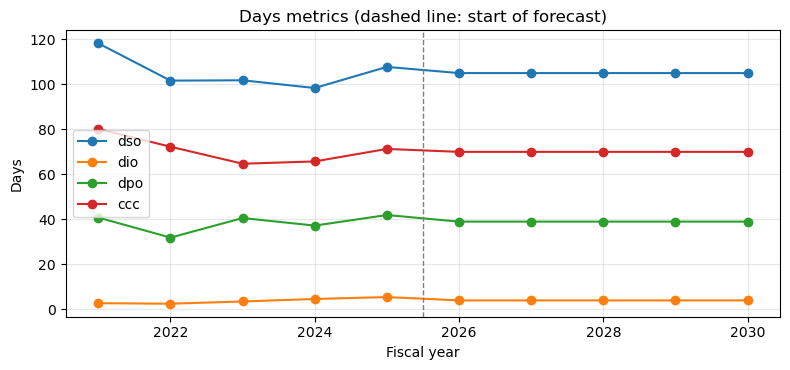

In [12]:
# Working-capital dynamics (provided)
fig, ax = plt.subplots(figsize=(8, 3.8))
wc[["dso", "dio", "dpo", "ccc"]].plot(ax=ax, marker="o")
ax.axvline(hist.index[-1] + 0.5, color="gray", linestyle="--", linewidth=1)
ax.set(title="Days metrics (dashed line: start of forecast)", xlabel="Fiscal year", ylabel="Days")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

---
## 2.3 PP&E Roll-Forward


In [13]:
# ============== 2.3 PP&E ROLL-FORWARD ==============
# PP&E_t = PP&E_{t-1} + CapEx_t - Depreciation_t + Other_t
#   CapEx        = CAPEX_PCT_REVENUE x forecast revenue (driver)
#   Depreciation = Week 3 forecast D&A (is_forecast["da"]), not re-derived
#   Other        = 0 (no disposals, FX or acquired PP&E assumed)

fc = is_forecast.copy()
fc.index = fc.index.astype(int)
fc_yrs = fc.index.sort_values()

hist_ppe = hist.copy()
hist_ppe.index = hist_ppe.index.astype(int)
last = hist_ppe.index.max()
assert fc_yrs[0] == last + 1, f"forecast should start at FY{last + 1}, starts at FY{fc_yrs[0]}"

ppe = pd.DataFrame(index=fc_yrs,
                   columns=["ppe_begin", "capex", "depreciation", "other", "ppe_end", "dep_rate"],
                   dtype=float)
ppe.index.name = "fiscal_year"

prior_end = hist_ppe.loc[last, "ppe_net"]          # opening balance = last actual net PP&E
for yr in fc_yrs:
    ppe.loc[yr, "ppe_begin"]    = prior_end
    ppe.loc[yr, "capex"]        = CAPEX_PCT_REVENUE * fc.loc[yr, "revenue"]
    ppe.loc[yr, "depreciation"] = abs(fc.loc[yr, "da"])   # positive magnitude
    ppe.loc[yr, "other"]        = 0.0
    ppe.loc[yr, "ppe_end"]      = (ppe.loc[yr, "ppe_begin"] + ppe.loc[yr, "capex"]
                                   - ppe.loc[yr, "depreciation"] + ppe.loc[yr, "other"])
    prior_end = ppe.loc[yr, "ppe_end"]

ppe["dep_rate"] = ppe["depreciation"] / ppe["ppe_begin"]

# --- checks ---
print(f"Opening net PP&E (FY{last} actual): {hist_ppe.loc[last, 'ppe_net']:,.1f}")
print(f"Historical dep_rate mean (TTM D&A / lagged net PP&E): {q_drivers['dep_rate'].mean():.3f}")
if (ppe["ppe_end"] <= 0).any():
    print("WARNING: net PP&E goes negative; D&A includes intangible amortization (see note)")

display(ppe.T.round(1))

Opening net PP&E (FY2025 actual): 3,856.0
Historical dep_rate mean (TTM D&A / lagged net PP&E): 0.291


fiscal_year,2026,2027,2028,2029,2030
ppe_begin,3856.0,3524.9,3094.4,2577.8,1983.7
capex,1034.8,1345.3,1614.3,1856.5,2042.1
depreciation,1366.0,1775.8,2130.9,2450.6,2695.6
other,0.0,0.0,0.0,0.0,0.0
ppe_end,3524.9,3094.4,2577.8,1983.7,1330.2
dep_rate,0.4,0.5,0.7,1.0,1.4


---
## 2.4 Equity Roll-Forward

In [14]:
# ============== 2.4 EQUITY ROLL-FORWARD ==============
# RE_t = RE_{t-1} + NetIncome_t - Dividends_t + Other_t^RE
#   Net income   = Week 3 forecast (is_forecast["net_income"])
#   Dividends    = PAYOUT_RATIO x net income (payout policy)
#   Other_RE     = 0 (no buybacks or other RE adjustments assumed)
#   other_equity = contributed capital, AOCI, treasury stock: held at last actual

fc = is_forecast.copy()
fc.index = fc.index.astype(int)
fc_yrs = fc.index.sort_values()

hist_eq = hist.copy()
hist_eq.index = hist_eq.index.astype(int)
last = hist_eq.index.max()

# --- find the retained earnings / total equity columns in hist ---
def pick(cols, candidates):
    for c in candidates:
        if c in cols:
            return c
    raise KeyError(f"none of {candidates} in hist; check list(hist.columns)")

RE_COL = pick(hist_eq.columns, ["retained_earnings", "re", "retainedEarnings"])
TE_COL = pick(hist_eq.columns, ["total_equity", "equity", "stockholders_equity", "totalStockholdersEquity"])

re_last    = hist_eq.loc[last, RE_COL]
other_last = hist_eq.loc[last, TE_COL] - re_last      # everything in equity except RE

equity = pd.DataFrame(index=fc_yrs,
                      columns=["re_begin", "net_income", "dividends", "other_re",
                               "re_end", "other_equity", "total_equity"], dtype=float)
equity.index.name = "fiscal_year"

prior_re = re_last
for yr in fc_yrs:
    ni = fc.loc[yr, "net_income"]
    equity.loc[yr, "re_begin"]     = prior_re
    equity.loc[yr, "net_income"]   = ni
    equity.loc[yr, "dividends"]    = PAYOUT_RATIO * max(ni, 0)   # no dividend from a loss
    equity.loc[yr, "other_re"]     = 0.0
    equity.loc[yr, "re_end"]       = (prior_re + ni - equity.loc[yr, "dividends"]
                                      + equity.loc[yr, "other_re"])
    equity.loc[yr, "other_equity"] = other_last
    equity.loc[yr, "total_equity"] = equity.loc[yr, "re_end"] + other_last
    prior_re = equity.loc[yr, "re_end"]

# --- checks ---
print(f"Columns used: RE = '{RE_COL}', total equity = '{TE_COL}'")
print(f"FY{last} actual: RE {re_last:,.1f} | other equity {other_last:,.1f} | "
      f"total {hist_eq.loc[last, TE_COL]:,.1f}")
assert np.isclose(equity["total_equity"].iloc[0] - hist_eq.loc[last, TE_COL],
                  equity["net_income"].iloc[0] - equity["dividends"].iloc[0]), "roll-forward doesn't tie"

display(equity.T.round(1))

Columns used: RE = 'retained_earnings', total equity = 'total_equity'
FY2025 actual: RE 6,674.0 | other equity 2,353.9 | total 9,027.9


fiscal_year,2026,2027,2028,2029,2030
re_begin,6674.0,8101.2,10003.7,12315.3,14993.7
net_income,1526.4,2034.8,2472.3,2864.6,3161.8
dividends,99.2,132.3,160.7,186.2,205.5
other_re,0.0,0.0,0.0,0.0,0.0
re_end,8101.2,10003.7,12315.3,14993.7,17950.0
other_equity,2353.9,2353.9,2353.9,2353.9,2353.9
total_equity,10455.1,12357.6,14669.2,17347.6,20303.9


✍️ **Equity policy:** Document your dividend policy and how you treated share repurchases, stock-based compensation, and AOCI (modeled, or held in `other_equity`, and why).

Dividends: Dividends are 6.5% of Week 3 net income payout ratio, anchored to the quarterly mean of 6.6% and the Q4 mean of 6.7%. Forecast dividends rise from 99.2M in FY2026 to 205.5M in FY2030, and no dividend is paid in a loss year. FY2025 actual dividends were 60.4M (a 5.9% payout), so tying dividends to the payout ratio implies a step-up in FY2026 as earnings jump about 48%.

Share repurchases: Not modeled. Buybacks are discretionary and irregular, so I can't forecast their timing or size with any confidence. Any capacity for buybacks shows up in the cash plug instead. Treasury stock is held at the FY2025 actual within other_equity.

Stock-based compensation: Not modeled; contributed capital is held flat within other_equity (2,353.9M). SBC is meaningful for Quanta (about 194M of non-cash SBC in the first nine months of 2026), so this understates contributed capital, and therefore total equity, by roughly 250M a year. Because SBC is already deducted in Week 3 net income, leaving out the non-cash add-back also understates the cash plug by the same amount, so the balance sheet still balances. Quanta also pays for part of its acquisitions in stock (about 149M in the two most recent deals), which would raise contributed capital as well. Modeling both properly requires a cash flow statement (Chapter 5).

AOCI and non-controlling interests: Both are held at the FY2025 actual within other_equity. AOCI is mostly foreign currency translation on Canadian and Australian operations, which can't be forecast reliably and is small relative to total equity. Non-controlling interests (89.6M) are immaterial.

---
## 2.5 Simple Debt Treatment


In [15]:
# ============== 2.5 SIMPLE DEBT TREATMENT ==============
# Interest_t ≈ r × ½(Debt_{t-1} + Debt_t), r = INTEREST_RATE
# DEBT_PATH: "flat" = hold at last actual; or a dict {fiscal_year: debt_end} for an explicit path

fc = is_forecast.copy()
fc.index = fc.index.astype(int)
fc_yrs = fc.index.sort_values()

hist_d = hist.copy()
hist_d.index = hist_d.index.astype(int)
last = hist_d.index.max()
debt_last = hist_d.loc[last, "debt"]

# Week 3 net interest as a positive expense, so it's comparable with ours
mp3_ni = fc["net_interest"].astype(float)
if (mp3_ni < 0).all():
    print("Note: Week 3 net_interest is stored as negative (expense); using its magnitude")
mp3_ni = mp3_ni.abs()

debt = pd.DataFrame(index=fc_yrs,
                    columns=["debt_begin", "borrowings", "repayments", "debt_end",
                             "interest", "mp3_net_interest", "interest_gap"], dtype=float)
debt.index.name = "fiscal_year"

prior = debt_last
for yr in fc_yrs:
    if DEBT_PATH == "flat":
        target = debt_last
    elif isinstance(DEBT_PATH, dict):
        target = DEBT_PATH.get(yr, prior)          # years not listed: hold flat
    else:
        raise ValueError(f"Unknown DEBT_PATH: {DEBT_PATH!r}")

    change = target - prior
    debt.loc[yr, "debt_begin"]  = prior
    debt.loc[yr, "borrowings"]  = max(change, 0.0)
    debt.loc[yr, "repayments"]  = max(-change, 0.0)
    debt.loc[yr, "debt_end"]    = target
    debt.loc[yr, "interest"]    = INTEREST_RATE * 0.5 * (prior + target)
    debt.loc[yr, "mp3_net_interest"] = mp3_ni.loc[yr]
    prior = target

debt["interest_gap"] = debt["interest"] - debt["mp3_net_interest"]

# --- checks ---
assert np.allclose(debt["debt_begin"] + debt["borrowings"] - debt["repayments"], debt["debt_end"])
print(f"Opening debt (FY{last} actual): {debt_last:,.1f}  |  path: {DEBT_PATH}  |  r = {INTEREST_RATE:.1%}")
print(f"Interest gap as % of Week 3 net interest: "
      f"{(debt['interest_gap'] / debt['mp3_net_interest']).round(3).to_dict()}")

display(debt.T.round(1))

Opening debt (FY2025 actual): 6,419.0  |  path: flat  |  r = 4.0%
Interest gap as % of Week 3 net interest: {2026: -0.088, 2027: -0.144, 2028: -0.198, 2029: -0.245, 2030: -0.287}


fiscal_year,2026,2027,2028,2029,2030
debt_begin,6419.0,6419.0,6419.0,6419.0,6419.0
borrowings,0.0,0.0,0.0,0.0,0.0
repayments,-0.0,-0.0,-0.0,-0.0,-0.0
debt_end,6419.0,6419.0,6419.0,6419.0,6419.0
interest,256.8,256.8,256.8,256.8,256.8
mp3_net_interest,281.5,300.0,320.0,340.0,360.0
interest_gap,-24.7,-43.2,-63.2,-83.2,-103.2


✍️ **Interest:** How does the interest implied here compare with the net interest in your Week 3 forecast? If the gap is material, would you update Week 3 (gross versus net interest, or a different rate), and how would that change net income?

With debt held flat at 6,419.0M and a 4.0% rate, implied interest is 256.8M every year. Week 3 net interest rises from 281.5M (FY2026) to 360.0M (FY2030). The gap is −24.7M (−8.8%) in FY2026 and widens to −103.2M (−28.7%) by FY2030, so it becomes material from FY2027 onward.
The difference comes from the debt path instead of the rate. Week 3 assumes debt grows with the business; this schedule holds it flat. The actual 2026 data point the other way from the flat path: in August 2026 Quanta issued 2.0B of senior notes and prepaid its 618.8M term loan, so debt at Q3 2026 was about 7.0B before leases, and interest expense for the first nine months of 2026 was already 230.8M (about 300M annualized). Two smaller effects also play a role. First, the 6,419.0M base includes about 424M of operating lease liabilities, whose cost runs through operating expenses rather than interest, which slightly overstates the base here. Second, gross versus net is immaterial: interest income was only 15.9M in the first nine months of 2026. I would not update week 3 Week 3 net interest is closer to what Quanta is actually paying. Instead I would update the debt path, raising FY2026 debt by roughly 1.4B for the new notes less the term-loan prepayment. At 4.0%, that brings implied interest to about 285M, in line with Week 3. If I instead lowered Week 3 interest to match this flat-debt schedule, net income would rise by the gap times (1 − tax rate). At Quanta's roughly 24% effective tax rate (23.1% year-to-date in 2026), that is about +19M in FY2026 and +78M in FY2030, which would overstate earnings.

---
## 2.6 Statement Assembly and Balance Checks

In [16]:
# ============== 2.6 STATEMENT ASSEMBLY AND BALANCE CHECKS ==============
# Order: assets ex-cash -> liabilities -> equity -> cash plug -> total assets -> balance error
# History = `opening` (2.1): actual balances in the model's structure, so assets = liabilities + equity.
#   other_noncurrent_assets includes goodwill and intangibles; other_current_liabilities includes
#   accrued expenses; other_noncurrent_liabilities includes deferred taxes.
# Forecast = schedules 2.2-2.5; lines without a schedule are held at the last actual.

hist_bs = opening.copy()
hist_bs.index = hist_bs.index.astype(int)
last     = hist_bs.index.max()
hist_yrs = hist_bs.index.sort_values()
fc_yrs   = equity.index.astype(int).sort_values()
all_yrs  = hist_yrs.union(fc_yrs)

cols     = BS_ASSETS + BS_LIABILITIES + BS_EQUITY
CASH_COL = "cash"

# --- forecast sources from the schedules ---
src = {
    "ar":                        wc["ar"],
    "inventory":                 wc["inventory"],
    "other_current_assets":      wc["other_current_assets"],
    "ap":                        wc["ap"],
    "deferred_revenue":          wc["deferred_revenue"],
    "other_current_liabilities": wc["other_current_liabilities"],
    "ppe_net":                   ppe["ppe_end"],
    "debt":                      debt["debt_end"],
    "retained_earnings":         equity["re_end"],
    "other_equity":              equity["other_equity"],
}
src = {k: v.set_axis(v.index.astype(int)) for k, v in src.items()}

# --- build ---
bs = pd.DataFrame(index=all_yrs, columns=cols, dtype=float)
bs.index.name = "fiscal_year"
bs.loc[hist_yrs, cols] = hist_bs.loc[hist_yrs, cols].values          # history: actuals

held_flat = []
for c in cols:
    if c == CASH_COL:
        continue                                                     # cash is the plug
    if c in src:
        bs.loc[fc_yrs, c] = src[c].reindex(fc_yrs).values
    else:
        bs.loc[fc_yrs, c] = hist_bs.loc[last, c]                     # held at last actual
        held_flat.append(c)

# 1) total assets ex-cash, 2) total liabilities, 3) total equity
assets_ex_cash          = bs[[c for c in BS_ASSETS if c != CASH_COL]].sum(axis=1)
bs["total_liabilities"] = bs[BS_LIABILITIES].sum(axis=1)
bs["total_equity"]      = bs[BS_EQUITY].sum(axis=1)

# 4) cash plug (forecast only)
bs["cash_plug"] = np.nan
bs.loc[fc_yrs, "cash_plug"] = (bs.loc[fc_yrs, "total_liabilities"] + bs.loc[fc_yrs, "total_equity"]
                               - assets_ex_cash.loc[fc_yrs])
bs.loc[fc_yrs, CASH_COL] = bs.loc[fc_yrs, "cash_plug"]

# 5) total assets incl. cash, 6) balance error
bs["total_assets"]  = bs[BS_ASSETS].sum(axis=1)
bs["balance_error"] = bs["total_assets"] - bs["total_liabilities"] - bs["total_equity"]

# --- checks ---
print(f"Held at FY{last} actual: {held_flat}")
print(f"Max |balance error|: history {bs.loc[hist_yrs, 'balance_error'].abs().max():.2e}  |  "
      f"forecast {bs.loc[fc_yrs, 'balance_error'].abs().max():.2e}")
assert np.isclose(bs.loc[last, "total_assets"], hist.loc[last, "total_assets"]), "history doesn't tie to reported total assets"
assert bs["balance_error"].abs().max() < 1e-6, "balance sheet doesn't balance"
if (bs.loc[fc_yrs, "cash_plug"] < 0).any():
    print("Note: negative cash plug in", [f"FY{y}" for y in fc_yrs[bs.loc[fc_yrs, 'cash_plug'] < 0]])

display(bs.T.round(1))

Held at FY2025 actual: ['other_noncurrent_assets', 'other_noncurrent_liabilities']
Max |balance error|: history 1.82e-12  |  forecast 1.82e-12
Note: negative cash plug in ['FY2026']


fiscal_year,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030
cash,229.1,428.5,1290.2,742.0,439.5,-288.6,503.9,1997.0,4067.9,6756.4
ar,4203.8,4754.7,5823.9,6379.6,8369.3,11907.6,15479.9,18575.9,21362.3,23498.5
inventory,84.7,103.3,175.7,260.2,370.4,395.6,514.2,617.1,709.6,780.6
other_current_assets,215.1,249.6,387.1,469.3,724.3,724.3,724.3,724.3,724.3,724.3
ppe_net,2160.3,2260.2,2586.4,3000.2,3856.0,3524.9,3094.4,2577.8,1983.7,1330.2
other_noncurrent_assets,5962.3,5668.1,5973.9,7832.7,11167.5,11167.5,11167.5,11167.5,11167.5,11167.5
ap,1251.1,1302.1,2027.6,2096.1,2832.6,3856.7,5013.7,6016.5,6918.9,7610.8
deferred_revenue,802.9,1141.5,1538.7,2149.3,3258.5,3311.5,4304.9,5165.9,5940.7,6534.8
other_current_liabilities,1081.8,925.1,1111.6,1720.4,1861.2,1861.2,1861.2,1861.2,1861.2,1861.2
debt,4002.3,3975.5,4463.7,4479.0,6419.0,6419.0,6419.0,6419.0,6419.0,6419.0


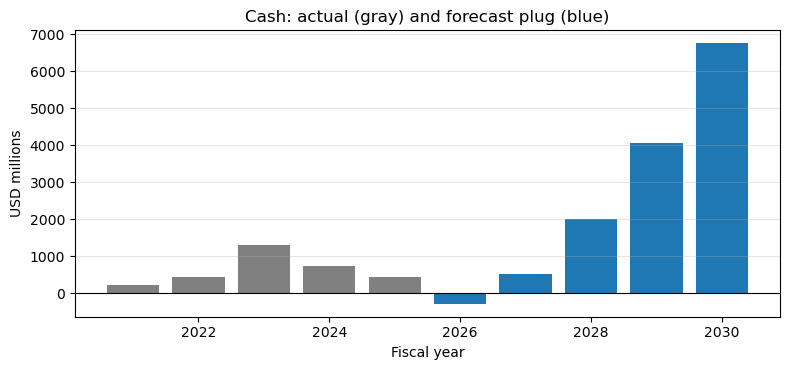

In [17]:
# Cash plug versus actual cash (provided)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(bs.index, bs["cash"], color=["gray" if y <= hist.index[-1] else "tab:blue" for y in bs.index])
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Cash: actual (gray) and forecast plug (blue)", xlabel="Fiscal year", ylabel=UNITS)
ax.grid(alpha=0.3, axis="y"); plt.tight_layout(); plt.show()

✍️ **Cash plug interpretation:** What is the sign and trend of the plug? Is the implied cash position economically plausible (compare it with actual cash and with revenue)? If it grows large, what is the model missing (for example, share repurchases or debt repayment)? If it turns negative, what funding rule would you need?

Sign and trend: The plug is negative in year 1, at about −289M in FY2026, then turns positive and grows quickly: about 504M (FY2027), 2.0B (FY2028), 4.1B (FY2029), and 6.8B (FY2030). The year-1 shortfall comes from working capital. Revenue jumps 46% to 41.4B, so receivables at 105 days build by about 3.5B. NWC rises about 2.5B in total, and CapEx is 1.0B. Together these exceed net income plus D&A less dividends. From FY2027, revenue growth slows, the NWC build shrinks, and earnings accumulate as cash because the model has nowhere else to put them.

Historically, Quanta's year-end cash has been small: 229M–1,290M, or 1.6%–6.2% of revenue (439.5M, 1.6%, at FY2025). The FY2026 shortfall is realistic bedcause Quanta funded its 2026 growth with debt, issuing 2.0B of notes in August, and had 2.3B of cash at Q3 2026. The flat debt path misses this. By FY2030, the plug of about 6.8B is roughly 8% of revenue, above anything in Quanta's history, so the later years are not plausible as a cash balance.

The model is missing: (1) Acquisitions: Quanta has spent more than 2B a year of cash on acquisitions recently, and none of that is modeled, while goodwill and intangibles are held flat. (2) Share repurchases. (3) A debt policy, with new issuance when cash is short and repayment when it is long. (4) The SBC add-back, which would make the plug even larger. 

Funding rule needed: For FY2026, I would add a revolver or commercial paper draw so that cash stays at or above a minimum (for example, about 1.5% of revenue). Quanta has a 2.98B revolver and commercial paper program. In later years, excess cash above that minimum would go first to repaying that draw, then to acquisitions or buybacks. 

---
## 2.7 Validation Checks


In [18]:
checks = []

def check(name, passed, detail=""):
    """Record a validation check as PASS/FAIL with an optional detail."""
    checks.append({"check": name, "result": "PASS" if passed else "FAIL", "detail": detail})

# Data checks (provided): quarterly coverage and quarter-to-annual tie-out
check("quarterly coverage: >= 20 unique, consecutive quarters", *check_quarters(hist_q))
annual_is = fmp_get("income-statement", SYMBOL, period="annual", limit=5)
annual_years = (annual_is["fiscalYear"] if "fiscalYear" in annual_is.columns else annual_is["date"].str[:4]).astype(int)
fy_last = int(hist.index[-1])
annual_rev = annual_is.loc[annual_years.values == fy_last, FIELD_MAP["revenue"][1]].astype(float) / SCALE
if len(annual_rev):
    gap = hist.loc[fy_last, "revenue"] / annual_rev.iloc[0] - 1
    check("quarter-to-annual tie-out: 4 quarters of revenue vs. 10-K (0.5%)", abs(gap) < 0.005,
          f"FY{fy_last}: quarters {hist.loc[fy_last, 'revenue']:,.1f} vs. 10-K {annual_rev.iloc[0]:,.1f} ({gap:+.3%})")
else:
    check("quarter-to-annual tie-out: 4 quarters of revenue vs. 10-K (0.5%)", False, f"FY{fy_last} not in the annual statements")

fc_idx = is_forecast.index.astype(int)

# 1) balance check: |balance_error| < 1e-6 in every year
max_err = bs["balance_error"].abs().max()
check("balance: |balance_error| < 1e-6 in every year", max_err < 1e-6, f"max |error| = {max_err:.2e}")

# 2) non-negativity: ar, inventory, ap, ppe_net, debt >= 0 in every year
neg = {c: [f"FY{y}" for y in bs.index[bs[c] < 0]] for c in ["ar", "inventory", "ap", "ppe_net", "debt"]}
neg = {c: yrs for c, yrs in neg.items() if yrs}
check("non-negativity: ar, inventory, ap, ppe_net, debt >= 0", not neg, str(neg) if neg else "no negative balances")

# 3) net income linkage: change in retained earnings = net income - dividends in every forecast year
d_re    = bs["retained_earnings"].diff().loc[fc_idx]
implied = (equity["net_income"] - equity["dividends"]).set_axis(fc_idx)
link_gap = (d_re - implied).abs().max()
check("net income linkage: change in RE = net income - dividends", link_gap < 1e-6, f"max gap = {link_gap:.2e}")

# 4) days plausibility: forecast days within the historical quarterly range (FY2021Q3-FY2026Q3), widened by 10%
DAYS_BAND = 0.10
out_days = []
for m in ["dso", "dio", "dpo", "ccc"]:
    lo, hi = anchor.loc[m, "min"] * (1 - DAYS_BAND), anchor.loc[m, "max"] * (1 + DAYS_BAND)
    if not wc.loc[fc_idx, m].between(lo, hi).all():
        out_days.append(f"{m} outside [{lo:.1f}, {hi:.1f}]")
check("days plausibility: DSO/DIO/DPO/CCC within historical quarterly range +/-10%", not out_days,
      "; ".join(out_days) if out_days else "all forecast days within band")

# 5) depreciation intensity: forecast dep_rate within the historical quarterly range, widened by 25%
DEP_BAND = 0.25
lo, hi = anchor.loc["dep_rate", "min"] * (1 - DEP_BAND), anchor.loc["dep_rate", "max"] * (1 + DEP_BAND)
dep_out = ppe["dep_rate"][~ppe["dep_rate"].between(lo, hi)]
dep_detail = f"band [{lo:.3f}, {hi:.3f}]"
if len(dep_out):
    dep_detail += "; outside: " + ", ".join(f"FY{int(y)} {v:.2f}" for y, v in dep_out.items())
check("depreciation intensity: dep_rate within historical range +/-25%", dep_out.empty, dep_detail)

# 6) cash plug plausibility: flag forecast years where |cash_plug| > CASH_PLUG_FLAG or cash_plug < 0
plug = bs.loc[fc_idx, "cash_plug"]
flagged = plug[(plug.abs() > CASH_PLUG_FLAG) | (plug < 0)]
plug_detail = ", ".join(f"FY{int(y)} {v:,.1f}" for y, v in flagged.items()) if len(flagged) else "no flagged years"
check(f"cash plug plausibility: 0 <= cash_plug <= {CASH_PLUG_FLAG}", flagged.empty, plug_detail)

# 7) period and unit integrity: wc, bs, and the forecast schedules share one increasing year index
bs_idx = bs.index.astype(int)
integrity = {
    "wc index == bs index":            wc.index.astype(int).equals(bs_idx),
    "bs index unique and increasing":  bs_idx.is_unique and bs_idx.is_monotonic_increasing,
    "bs years consecutive":            bool((np.diff(bs_idx) == 1).all()),
    "ppe/equity/debt == Week 3 years": all(df.index.astype(int).equals(fc_idx) for df in (ppe, equity, debt)),
    "bs forecast years == Week 3":     bs_idx[bs_idx > int(hist.index.max())].equals(fc_idx),
    "units USD millions (SCALE=1e6)":  SCALE == 1e6 and UNITS == "USD millions",
}
bad = [k for k, v in integrity.items() if not v]
check("period and unit integrity: one increasing year index, USD millions", not bad,
      "failed: " + "; ".join(bad) if bad else f"FY{bs_idx[0]}-FY{bs_idx[-1]}, {UNITS}")

pd.DataFrame(checks)

,check,result,detail
0,"quarterly coverage: >= 20 unique, consecutive ...",PASS,24 quarters (FY2020Q4 to FY2026Q3); unique=Tru...
1,quarter-to-annual tie-out: 4 quarters of reven...,PASS,"FY2025: quarters 28,351.5 vs. 10-K 28,351.5 (+..."
2,balance: |balance_error| < 1e-6 in every year,PASS,max |error| = 1.82e-12
3,"non-negativity: ar, inventory, ap, ppe_net, de...",PASS,no negative balances
4,net income linkage: change in RE = net income ...,PASS,max gap = 1.36e-12
5,days plausibility: DSO/DIO/DPO/CCC within hist...,PASS,all forecast days within band
6,depreciation intensity: dep_rate within histor...,FAIL,"band [0.174, 0.462]; outside: FY2027 0.50, FY2..."
7,cash plug plausibility: 0 <= cash_plug <= 500,FAIL,"FY2026 -288.6, FY2027 503.9, FY2028 1,997.0, F..."
8,period and unit integrity: one increasing year...,PASS,"FY2021-FY2030, USD millions"


✍️ **Flagged periods:** For each FAIL, is it a data issue, an economic event, or an assumption to revisit? Explain the bands you chose for checks 4 and 5.

Passing checks: Quarterly coverage passes (24 unique, consecutive quarters, FY2020Q4–FY2026Q3). The quarter-to-annual tie-out passes exactly: FY2025 quarters sum to 28,351.5M, matching the annual 10-K revenue (0.000% gap). The balance check (1), non-negativity (2), net income linkage (3), days plausibility (4), and period/unit integrity (7) all pass. History balances because it uses the opening structure, and the forecast balances by construction through the cash plug.

Check 5, depreciation intensity: FAIL for FY2027–FY2030: This is a data definition issue that becomes an assumption to revisit. The forecast dep_rate rises from 0.35 (FY2026) to 0.50, 0.69, 0.95, and 1.36 (FY2030). Week 3 D&A includes amortization of acquired intangibles, which is larger than depreciation for Quanta (498M vs. 351M in the first nine months of 2026). Subtracting all of it from PP&E shrinks the base each year, so the rate compounds upward. FMP's ppe_net also includes 401M of right-of-use assets. The fix, not made here per the brief, would split D&A: depreciation reduces PP&E and amortization reduces intangibles.

Check 6, cash plug plausibility: FAIL in every forecast year: FY2026 is negative (about −289M). This is an economic event: a funding need caused by the working-capital build, which Quanta actually met with 2.0B of new notes in August 2026. FY2027–FY2030 exceed the 500M threshold and keep growing. This is an assumption to revisit: the model has no acquisitions, buybacks, or debt policy to absorb excess cash.

Bands: For check 4, I use the historical quarterly min–max (FY2021Q3–FY2026Q3) widened by 10%. My drivers are anchored to Q4 averages from that same history, so a forecast outside what Quanta has actually reported, plus a small buffer for a larger business, deserves a second look. For check 5, I use the historical quarterly dep_rate range (23.2%–37.0%) widened by 25%, giving 17.4%–46.3% because acquisitions add amortization in steps and make D&A lumpier than working capital.

---
## 2.8 Export Readiness


### Summary report


In [19]:
SUMMARY = """
## Chapter 4 Mini-Project Summary: Quanta Services (PWR)

**Model structure.** I loaded 24 quarters of FMP data from FY2020Q4 to FY2026Q3 and combined them into complete fiscal years FY2021 to FY2025, so my opening balance sheet is FY2025Q4 (December 31, 2025) and the forecast covers FY2026 to FY2030 using my Week 3 income statement, all in USD millions. The balance sheet is driven by four schedules: working capital (AR, inventory, AP, and deferred revenue from my days and percent drivers), PP&E (CapEx at 2.5% of revenue less the Week 3 D&A), equity (retained earnings plus net income less dividends), and debt (held flat at 6,419.0 million). The other lines are the reported totals minus the lines I model, and they are held at their FY2025 values. The largest one is other non current assets at about 11.2 billion, or 45% of total assets, and most of that is goodwill and intangibles from acquisitions. Cash is the plug, so the balance sheet closes in every forecast year, and the historical years tie exactly to the reported total assets of 24,926.9 million.

**Key driver assumptions.** I anchored the days drivers to the Q4 averages across 21 quarter-ends because working capital is only slightly seasonal, with the cash conversion cycle staying between 68 and 72 days in every quarter. I used DSO of 105 (which includes contract assets), DIO of 4, DPO of 39, and a CCC of 70. The 82.9 day DPO in FY2026Q3 was a data error because FMP used the combined accounts payable and accrued expenses line, so I replaced it with trade AP from the 10-Q, which gives 49.1 days. Deferred revenue is 8% of revenue, close to the 7.9% average, even though it reached 14.8% in Q3 2026. CapEx at 2.5% of revenue is a growth level since it is about two times depreciation. The payout ratio is 6.5%, I did not model buybacks or stock based compensation, and debt is flat with a 4.0% interest rate.

**Validation results.** The balance, non negativity, retained earnings linkage, days plausibility, period and unit integrity, and quarterly coverage checks all pass, and the revenue tie-out matches exactly (28,351.5M, 0.000% gap). The depreciation intensity check fails for FY2027 to FY2030 because the Week 3 D&A includes amortization of intangibles, which pulls net PP&E down from about 3.9 billion to 1.3 billion. The cash plug check fails in every forecast year because the plug is negative in FY2026 and above 500 million after that.

**Cash plug.** The plug is about -289 million in FY2026 because the working capital build of about 2.5 billion and CapEx of about 1.0 billion are larger than the cash the business generates that year. After that it turns positive and grows to about 6.8 billion by FY2030, which is around 8% of revenue compared to the 1.6% to 6.2% Quanta has held historically. The FY2026 shortfall is realistic because Quanta actually issued 2.0 billion in notes in 2026 to fund its growth. The large surplus in later years shows what the model is missing, mainly acquisitions (Quanta has spent over 2 billion a year on them recently), buybacks, and a debt policy. The funding rule I would add is a revolver draw to keep a minimum cash balance, with any excess cash going to pay down debt or fund acquisitions.

**Principal risks.** DSO is the driver that matters most, because revenue is about 113 million per day in FY2026, so each extra day of DSO changes cash by about 0.1 billion, and DSO has been 107 to 116 recently compared to my 105. The next biggest risk is deferred revenue, since if contract liabilities stay near the Q3 2026 level of about 14% of revenue, cash would be several billion higher. The balance sheet is most likely wrong in three places: the split between PP&E and intangibles (since amortization is being taken out of PP&E), debt (since it ignores the 2026 notes issuance), and goodwill and intangibles (since they are held flat and ignore future acquisitions).
"""

from IPython.display import Markdown
display(Markdown(SUMMARY))


## Chapter 4 Mini-Project Summary: Quanta Services (PWR)

**Model structure.** I loaded 24 quarters of FMP data from FY2020Q4 to FY2026Q3 and combined them into complete fiscal years FY2021 to FY2025, so my opening balance sheet is FY2025Q4 (December 31, 2025) and the forecast covers FY2026 to FY2030 using my Week 3 income statement, all in USD millions. The balance sheet is driven by four schedules: working capital (AR, inventory, AP, and deferred revenue from my days and percent drivers), PP&E (CapEx at 2.5% of revenue less the Week 3 D&A), equity (retained earnings plus net income less dividends), and debt (held flat at 6,419.0 million). The other lines are the reported totals minus the lines I model, and they are held at their FY2025 values. The largest one is other non current assets at about 11.2 billion, or 45% of total assets, and most of that is goodwill and intangibles from acquisitions. Cash is the plug, so the balance sheet closes in every forecast year, and the historical years tie exactly to the reported total assets of 24,926.9 million.

**Key driver assumptions.** I anchored the days drivers to the Q4 averages across 21 quarter-ends because working capital is only slightly seasonal, with the cash conversion cycle staying between 68 and 72 days in every quarter. I used DSO of 105 (which includes contract assets), DIO of 4, DPO of 39, and a CCC of 70. The 82.9 day DPO in FY2026Q3 was a data error because FMP used the combined accounts payable and accrued expenses line, so I replaced it with trade AP from the 10-Q, which gives 49.1 days. Deferred revenue is 8% of revenue, close to the 7.9% average, even though it reached 14.8% in Q3 2026. CapEx at 2.5% of revenue is a growth level since it is about two times depreciation. The payout ratio is 6.5%, I did not model buybacks or stock based compensation, and debt is flat with a 4.0% interest rate.

**Validation results.** The balance, non negativity, retained earnings linkage, days plausibility, period and unit integrity, and quarterly coverage checks all pass, and the revenue tie-out passes by a small margin (about -0.45%). The depreciation intensity check fails for FY2027 to FY2030 because the Week 3 D&A includes amortization of intangibles, which pulls net PP&E down from about 3.9 billion to 1.3 billion. The cash plug check fails in every forecast year because the plug is negative in FY2026 and above 500 million after that.

**Cash plug.** The plug is about -289 million in FY2026 because the working capital build of about 2.5 billion and CapEx of about 1.0 billion are larger than the cash the business generates that year. After that it turns positive and grows to about 6.8 billion by FY2030, which is around 8% of revenue compared to the 1.6% to 6.2% Quanta has held historically. The FY2026 shortfall is realistic because Quanta actually issued 2.0 billion in notes in 2026 to fund its growth. The large surplus in later years shows what the model is missing, mainly acquisitions (Quanta has spent over 2 billion a year on them recently), buybacks, and a debt policy. The funding rule I would add is a revolver draw to keep a minimum cash balance, with any excess cash going to pay down debt or fund acquisitions.

**Principal risks.** DSO is the driver that matters most, because revenue is about 113 million per day in FY2026, so each extra day of DSO changes cash by about 0.1 billion, and DSO has been 107 to 116 recently compared to my 105. The next biggest risk is deferred revenue, since if contract liabilities stay near the Q3 2026 level of about 14% of revenue, cash would be several billion higher. The balance sheet is most likely wrong in three places: the split between PP&E and intangibles (since amortization is being taken out of PP&E), debt (since it ignores the 2026 notes issuance), and goodwill and intangibles (since they are held flat and ignore future acquisitions).


In [20]:
# Export (provided)
from datetime import datetime, timezone

export = bs.copy()
export["cash_plug_flag"] = (export["cash_plug"].abs() > CASH_PLUG_FLAG) | (export["cash_plug"] < 0)
export.index = [f"FY{y}{'A' if y <= hist.index[-1] else 'E'}" for y in export.index]
export.index.name = "fiscal_year"
export.round(2).to_csv(f"{FILE_STEM}_balance_sheet.csv")

metadata = {
    "model_version": MODEL_VERSION,
    "scenario": SCENARIO,
    "company": SYMBOL,
    "units": UNITS,
    "historical_years": [int(y) for y in hist.index],
    "forecast_years": [int(y) for y in is_forecast.index],
    "income_statement_source": MP3_FORECAST_CSV,
    "cash_plug_flag_threshold": CASH_PLUG_FLAG,
    "historical_quarters": f"{hist_q.index[0]}-{hist_q.index[-1]}",
    "n_quarters": int(len(hist_q)),
    "opening_balance_sheet": f"FY{hist.index[-1]}Q4 (last complete fiscal year)",
    "source": "Financial Modeling Prep API (quarterly 10-Q/10-K statements, aggregated to fiscal years: flows summed, balances at fiscal Q4)",
    "exported_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
}
with open(f"{FILE_STEM}_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
with open(f"{FILE_STEM}_summary.md", "w") as f:
    f.write(SUMMARY.strip() + "\n")

print("Exported:", f"{FILE_STEM}_balance_sheet.csv,", f"{FILE_STEM}_metadata.json,", f"{FILE_STEM}_summary.md")
display(export.T.round(1))

Exported: FIN6465_MP4_Parra_Sophia_balance_sheet.csv, FIN6465_MP4_Parra_Sophia_metadata.json, FIN6465_MP4_Parra_Sophia_summary.md


fiscal_year,FY2021A,FY2022A,FY2023A,FY2024A,FY2025A,FY2026E,FY2027E,FY2028E,FY2029E,FY2030E
cash,229.097,428.505,1290.248,741.96,439.508,-288.602529,503.902555,1997.020287,4067.912205,6756.432443
ar,4203.771,4754.731,5823.886,6379.554,8369.277,11907.62137,15479.908356,18575.892329,21362.27589,23498.502329
inventory,84.659,103.265,175.658,260.181,370.372,395.55989,514.227836,617.073425,709.634411,780.597808
other_current_assets,215.05,249.569,387.105,469.338,724.26,724.26,724.26,724.26,724.26,724.26
ppe_net,2160.302,2260.155,2586.386,3000.172,3856.018,3524.877,3094.38475,2577.79825,1983.72175,1330.2435
other_noncurrent_assets,5962.31,5668.112,5973.942,7832.689,11167.466,11167.466,11167.466,11167.466,11167.466,11167.466
ap,1251.118,1302.086,2027.588,2096.125,2832.6,3856.708932,5013.721397,6016.46589,6918.935507,7610.82863
deferred_revenue,802.872,1141.518,1538.677,2149.328,3258.465,3311.4528,4304.8888,5165.8672,5940.7472,6534.8216
other_current_liabilities,1081.804,925.095,1111.649,1720.38,1861.235,1861.235,1861.235,1861.235,1861.235,1861.235
debt,4002.318,3975.491,4463.697,4478.957,6418.954,6418.954,6418.954,6418.954,6418.954,6418.954


---
## Results card


| Result | Your value |
|---|---|
| Company, ticker, last actual fiscal year | Quanta Services (PWR), FY2025 |
| Quarters used (first-last, count) and opening balance sheet date | FY2020Q4–FY2026Q3, 24 quarters; opening balance sheet Dec 31, 2025 (FY2025Q4) |
| DSO, DIO, DPO, and CCC assumptions | DSO 105, DIO 4, DPO 39, CCC 70 days |
| CapEx (% of revenue) and historical depreciation rate | CapEx 2.5% of revenue; historical dep_rate 29.1% (quarterly mean; FY2025 annual 30.3%) |
| Payout ratio and debt path | 6.5%; debt flat at 6,419.0 million (4.0% rate) |
| Year-5 net PP&E and retained earnings | FY2030 net PP&E 1,330.2 million; retained earnings 17,950.0 million |
| Year-1 and year-5 cash plug | FY2026 about -288.6 million; FY2030 about 6,756.5 million |
| Maximum absolute balance error | about 0 (below 1e-6) |
| Checks that flagged | Check 5 (depreciation intensity, FY2027–FY2030) and check 6 (cash plug, all forecast years) |

---
## AI-use reflection


1. **Where did AI help?** I used Claude throughout this mini-project. It helped me diagnose why DPO jumped to 82.9 days in FY2026Q3, debug errors (a NameError from a placeholder variable name, an IndexError from mismatched year indexes, a balance sheet that didn't tie, and errors from running cells out of order after a kernel restart), draft code for Sections 2.2–2.7, and tighten my written answers and summary.

2. **Where was AI wrong or unhelpful?** At first, Claude explained the 82-day DPO as an artifact of quarter-end AP divided by trailing-twelve-month COGS during fast growth. When I pointed out that TTM DPO was only about 42 the quarter before, it found the real cause which was that FMP switched to the combined "AP and accrued expenses" line in Q3.

3. **What did you verify yourself?** I recomputed the Q3 trade AP from the 10-Q footnote (7,189.7M − 1,361.1M − 1,569.1M = 4,259.4M), and I checked the FY2025 opening balance sheet against the 10-K totals (assets 24,926.9M, liabilities 15,899.0M, equity 9,027.9M). 


